In [4]:
import os
import re
import math
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi

# Reproducibility
np.random.seed(42)


In [21]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.9/914.9 kB 15.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 34.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]


APG RAG Demo



In [8]:
# =========================
# 1) LOAD DOCUMENTS (20 Newsgroups)
# =========================
from dataclasses import dataclass
from typing import Dict, List
import re

from sklearn.datasets import fetch_20newsgroups

@dataclass
class Document:
    doc_id: str
    text: str
    metadata: Dict

def load_20newsgroups(subset: str = "train", remove=("headers", "footers", "quotes")) -> List[Document]:
    data = fetch_20newsgroups(subset=subset, remove=remove)
    docs: List[Document] = []
    for i, txt in enumerate(data.data):
        docs.append(Document(
            doc_id=f"20ng_{subset}_{i}",
            text=txt,
            metadata={"topic_id": int(data.target[i]), "topic": data.target_names[int(data.target[i])]},
        ))
    return docs

docs = load_20newsgroups(subset="train")
print("Documents:", len(docs))
print("Example metadata:", docs[0].metadata)
print(docs[0].text[:400])

Documents: 11314
Example metadata: {'topic_id': 7, 'topic': 'rec.autos'}
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, h


Documents: 8925
Topics: 20


,topic,n_docs
0,soc.religion.christian,536
1,sci.med,507
2,sci.crypt,507
3,sci.space,478
4,comp.sys.ibm.pc.hardware,477
5,comp.windows.x,476
6,rec.sport.hockey,472
7,sci.electronics,470
8,talk.politics.mideast,465
9,talk.politics.guns,457


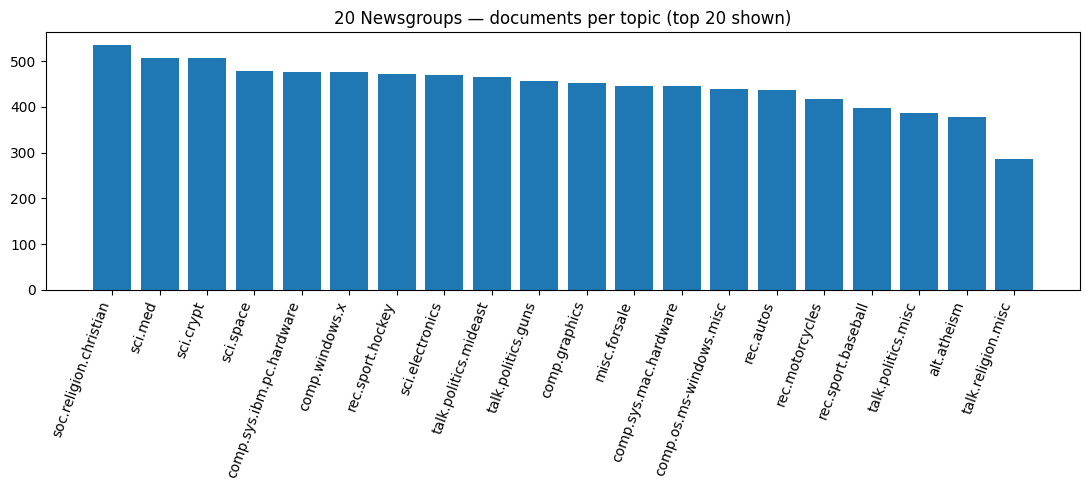


Length stats (words):


,n_words
count,8925.000000
mean,228.523810
std,570.344194
min,11.000000
10%,45.000000
50%,110.000000
90%,396.600000
95%,682.800000
99%,2059.360000
max,11765.000000


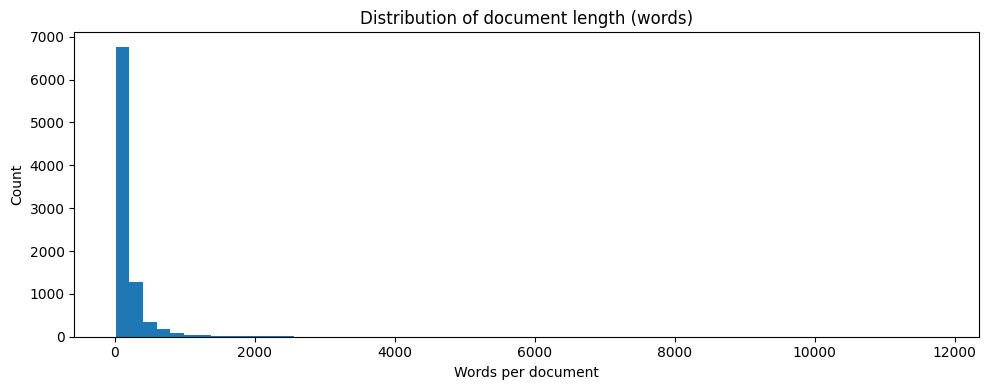

,doc_id,topic,n_words,n_paras
1716,20ng_train_2191,soc.religion.christian,43,1
1954,20ng_train_2491,soc.religion.christian,362,3
2384,20ng_train_3019,soc.religion.christian,107,3


In [12]:
# =========================
# Overview of 20 Newsgroups corpus (topics, counts, lengths)
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Build a doc-level dataframe
df_docs = pd.DataFrame([{
    "doc_id": d.doc_id,
    "topic_id": d.metadata["topic_id"],
    "topic": d.metadata["topic"],
    "n_chars": len(d.text),
    "n_words": len(d.text.split()),
    "n_paras": max(1, d.text.count("\n\n") + 1),
} for d in docs])

print("Documents:", len(df_docs))
print("Topics:", df_docs["topic"].nunique())

# 1) Topic counts (table)
topic_counts = (df_docs["topic"].value_counts()
                .rename_axis("topic")
                .reset_index(name="n_docs"))
display(topic_counts.head(20))

# 2) Plot: docs per topic
plt.figure(figsize=(11, 5))
plt.bar(topic_counts["topic"][:20], topic_counts["n_docs"][:20])
plt.xticks(rotation=70, ha="right")
plt.title("20 Newsgroups — documents per topic (top 20 shown)")
plt.tight_layout()
plt.show()

# 3) Basic length stats
print("\nLength stats (words):")
display(df_docs["n_words"].describe(percentiles=[0.1, 0.5, 0.9, 0.95, 0.99]).to_frame())

# 4) Plot: distribution of document lengths (words)
plt.figure(figsize=(10, 4))
plt.hist(df_docs["n_words"], bins=60)
plt.title("Distribution of document length (words)")
plt.xlabel("Words per document")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 5) Optional: inspect a topic
example_topic = topic_counts["topic"].iloc[0]
sample = df_docs[df_docs["topic"] == example_topic].sample(3, random_state=42)[["doc_id","topic","n_words","n_paras"]]
display(sample)


In [9]:
# =========================
# 2) CLEAN TEXT
# =========================
def clean_text(text: str) -> str:
    # Normalize line breaks
    text = text.replace("\r\n", "\n").replace("\r", "\n")

    # Remove common email artifacts still present after remove=(...)
    text = re.sub(r"^\s*>.*$", "", text, flags=re.MULTILINE)        # quoted lines
    text = re.sub(r"^\s*\|.*$", "", text, flags=re.MULTILINE)       # pipe quotes
    text = re.sub(r"http\S+", " ", text)                            # urls

    # Collapse whitespace
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

for d in docs:
    d.text = clean_text(d.text)

# Drop very short docs (optional, improves chunking)
docs = [d for d in docs if len(d.text) > 200]

print("After cleaning/filtering:", len(docs))
print(docs[0].text[:400])


After cleaning/filtering: 8925
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, h


In [ ]:
# =========================
# 3) CHUNKING STRATEGIES
#    (workshop-stable: simple whitespace tokenization)
# =========================
from dataclasses import dataclass
from typing import Optional

def simple_tokenize(text: str) -> List[str]:
    return text.split()

def detokenize(tokens: List[str]) -> str:
    return " ".join(tokens)

@dataclass
class Chunk:
    chunk_id: str
    doc_id: str
    text: str
    metadata: Dict

def chunk_fixed_tokens(doc: Document, chunk_size: int = 200, overlap: int = 50) -> List[Chunk]:
    tokens = simple_tokenize(doc.text)
    chunks: List[Chunk] = []
    start, idx = 0, 0

    while start < len(tokens):
        end = min(start + chunk_size, len(tokens))
        chunk_tokens = tokens[start:end]
        chunk_text = detokenize(chunk_tokens)

        chunks.append(Chunk(
            chunk_id=f"{doc.doc_id}__c{idx}",
            doc_id=doc.doc_id,
            text=chunk_text,
            metadata={**doc.metadata, "chunk_index": idx, "method": "fixed_tokens",
                      "chunk_size": chunk_size, "overlap": overlap}
        ))

        idx += 1
        if end == len(tokens):
            break
        start = max(0, end - overlap)

    return chunks

def chunk_paragraphs(doc: Document, max_tokens: int = 220) -> List[Chunk]:
    paras = [p.strip() for p in doc.text.split("\n\n") if p.strip()]
    chunks: List[Chunk] = []
    idx = 0
    buffer: List[str] = []

    for p in paras:
        p_tokens = simple_tokenize(p)

        # Very long paragraph → fallback to fixed chunking
        if len(p_tokens) > max_tokens:
            if buffer:
                chunks.append(Chunk(
                    chunk_id=f"{doc.doc_id}__c{idx}",
                    doc_id=doc.doc_id,
                    text=detokenize(buffer),
                    metadata={**doc.metadata, "chunk_index": idx, "method": "paragraphs"}
                ))
                idx += 1
                buffer = []

            temp = Document(doc_id=doc.doc_id, text=p, metadata=doc.metadata)
            sub = chunk_fixed_tokens(temp, chunk_size=max_tokens, overlap=40)
            for s in sub:
                s.chunk_id = f"{doc.doc_id}__c{idx}"
                s.metadata["chunk_index"] = idx
                s.metadata["method"] = "paragraphs_fallback_fixed"
                idx += 1
                chunks.append(s)
            continue

        if len(buffer) + len(p_tokens) <= max_tokens:
            buffer.extend(p_tokens)
        else:
            chunks.append(Chunk(
                chunk_id=f"{doc.doc_id}__c{idx}",
                doc_id=doc.doc_id,
                text=detokenize(buffer),
                metadata={**doc.metadata, "chunk_index": idx, "method": "paragraphs"}
            ))
            idx += 1
            buffer = p_tokens

    if buffer:
        chunks.append(Chunk(
            chunk_id=f"{doc.doc_id}__c{idx}",
            doc_id=doc.doc_id,
            text=detokenize(buffer),
            metadata={**doc.metadata, "chunk_index": idx, "method": "paragraphs"}
        ))

    return chunks

def build_chunks(docs: List[Document], strategy: str, limit_docs: Optional[int] = None, **kwargs) -> List[Chunk]:
    use_docs = docs[:limit_docs] if limit_docs else docs
    all_chunks: List[Chunk] = []
    for d in use_docs:
        if strategy == "fixed_tokens":
            all_chunks.extend(chunk_fixed_tokens(d, **kwargs))
        elif strategy == "paragraphs":
            all_chunks.extend(chunk_paragraphs(d, **kwargs))
        else:
            raise ValueError("strategy must be 'fixed_tokens' or 'paragraphs'")
    return all_chunks

# For workshop speed: limit docs (increase later)
chunks = build_chunks(docs, strategy="fixed_tokens", limit_docs=400, chunk_size=180, overlap=40)

print("Docs used:", len({c.doc_id for c in chunks}))
print("Total chunks:", len(chunks))
print("Example chunk:\n", chunks[0].chunk_id, "\n", chunks[0].text[:300])


Docs used: 400
Total chunks: 721
Example chunk:
 20ng_train_0__c0 
 I was wondering if anyone out there could enlighten me on this car I saw the other day. It was a 2-door sports car, looked to be from the late 60s/ early 70s. It was called a Bricklin. The doors were really small. In addition, the front bumper was separate from the rest of the body. This is all I kn


In [13]:
import pandas as pd
import numpy as np

def chunk_stats(chunks):
    df = pd.DataFrame([{
        "chunk_id": c.chunk_id,
        "doc_id": c.doc_id,
        "topic": c.metadata.get("topic"),
        "method": c.metadata.get("method"),
        "n_words": len(c.text.split()),
        "n_chars": len(c.text),
        "chunk_index": c.metadata.get("chunk_index", None),
    } for c in chunks])
    return df

def preview_chunks_for_doc(chunks, doc_id, n=5, max_chars=350):
    subset = [c for c in chunks if c.doc_id == doc_id]
    subset = sorted(subset, key=lambda x: x.metadata.get("chunk_index", 0))
    rows = []
    for c in subset[:n]:
        rows.append({
            "chunk_id": c.chunk_id,
            "n_words": len(c.text.split()),
            "preview": (c.text[:max_chars] + "…") if len(c.text) > max_chars else c.text
        })
    return pd.DataFrame(rows)

# Example: stats + preview
df_chunks = chunk_stats(chunks)
print("Total chunks:", len(df_chunks))
display(df_chunks["n_words"].describe(percentiles=[0.1,0.5,0.9,0.95,0.99]).to_frame())

example_doc_id = df_chunks["doc_id"].iloc[0]
display(preview_chunks_for_doc(chunks, example_doc_id, n=6))


Total chunks: 721


,n_words
count,721.000000
mean,130.811373
std,52.928048
min,34.000000
10%,51.000000
50%,152.000000
90%,180.000000
95%,180.000000
99%,180.000000
max,180.000000


,chunk_id,n_words,preview
0,20ng_train_0__c0,91,I was wondering if anyone out there could enli...


In [14]:
import pandas as pd
import numpy as np

def chunk_stats(chunks):
    df = pd.DataFrame([{
        "chunk_id": c.chunk_id,
        "doc_id": c.doc_id,
        "topic": c.metadata.get("topic"),
        "method": c.metadata.get("method"),
        "n_words": len(c.text.split()),
        "n_chars": len(c.text),
        "chunk_index": c.metadata.get("chunk_index", None),
    } for c in chunks])
    return df

def preview_chunks_for_doc(chunks, doc_id, n=5, max_chars=350):
    subset = [c for c in chunks if c.doc_id == doc_id]
    subset = sorted(subset, key=lambda x: x.metadata.get("chunk_index", 0))
    rows = []
    for c in subset[:n]:
        rows.append({
            "chunk_id": c.chunk_id,
            "n_words": len(c.text.split()),
            "preview": (c.text[:max_chars] + "…") if len(c.text) > max_chars else c.text
        })
    return pd.DataFrame(rows)

# Example: stats + preview
df_chunks = chunk_stats(chunks)
print("Total chunks:", len(df_chunks))
display(df_chunks["n_words"].describe(percentiles=[0.1,0.5,0.9,0.95,0.99]).to_frame())

example_doc_id = df_chunks["doc_id"].iloc[0]
display(preview_chunks_for_doc(chunks, example_doc_id, n=6))

Total chunks: 721


,n_words
count,721.000000
mean,130.811373
std,52.928048
min,34.000000
10%,51.000000
50%,152.000000
90%,180.000000
95%,180.000000
99%,180.000000
max,180.000000


,chunk_id,n_words,preview
0,20ng_train_0__c0,91,I was wondering if anyone out there could enli...


In [15]:
import re
from html import escape
from IPython.display import HTML, display

# Simple tokenization that keeps punctuation as separate tokens (looks nicer)
TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)

def tokenize_with_punct(text: str):
    return TOKEN_RE.findall(text)

def build_fixed_token_spans(tokens, chunk_size=180, overlap=40):
    """
    Returns:
      spans: list of (start_idx, end_idx) token indices for each chunk
      membership: list[int] how many chunks include each token (for overlap highlighting)
    """
    spans = []
    start = 0
    idx = 0
    n = len(tokens)

    membership = [0] * n

    while start < n:
        end = min(start + chunk_size, n)
        spans.append((start, end))
        # membership counts (to detect overlap)
        for i in range(start, end):
            membership[i] += 1

        idx += 1
        if end == n:
            break
        start = max(0, end - overlap)

    return spans, membership

def render_chunks_as_colored_text(doc_text: str, chunk_size=180, overlap=40, max_tokens=1200, title=None):
    tokens = tokenize_with_punct(doc_text)
    if len(tokens) > max_tokens:
        tokens = tokens[:max_tokens] + ["…"]
        truncated = True
    else:
        truncated = False

    spans, membership = build_fixed_token_spans(tokens, chunk_size=chunk_size, overlap=overlap)

    # assign each token a primary chunk (first chunk that covers it)
    token_chunk = [-1] * len(tokens)
    for ci, (s, e) in enumerate(spans):
        for i in range(s, e):
            if token_chunk[i] == -1:
                token_chunk[i] = ci

    # palette: repeating soft colors
    colors = [
        "#fff3bf", "#d3f9d8", "#d0ebff", "#ffd8a8", "#eebefa",
        "#c5f6fa", "#ffe3e3", "#e7f5ff", "#f3d9fa", "#d8f5a2"
    ]

    # CSS for nice rendering
    css = f"""
    <style>
      .chunkwrap {{
        font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, "Liberation Mono", monospace;
        font-size: 13px;
        line-height: 1.65;
        white-space: normal;
        word-wrap: break-word;
        border: 1px solid #ddd;
        border-radius: 12px;
        padding: 14px 16px;
      }}
      .tok {{
        padding: 0px 2px;
        margin: 0px 1px;
        border-radius: 4px;
        display: inline-block;
      }}
      .overlap {{
        outline: 1px dashed rgba(0,0,0,0.35);
        outline-offset: -1px;
      }}
      .legend {{
        font-family: system-ui, -apple-system, Segoe UI, Roboto, Helvetica, Arial;
        font-size: 12px;
        color: #444;
        margin-bottom: 8px;
      }}
      .chip {{
        display: inline-block;
        padding: 2px 8px;
        border-radius: 999px;
        border: 1px solid #ddd;
        margin-right: 6px;
      }}
    </style>
    """

    # Legend
    legend = f"""
    <div class="legend">
      <span class="chip">chunk_size={chunk_size}</span>
      <span class="chip">overlap={overlap}</span>
      <span class="chip">chunks={len(spans)}</span>
      <span class="chip">tokens_shown={len(tokens)}{' (truncated)' if truncated else ''}</span>
      <span class="chip">overlap = dashed outline</span>
    </div>
    """

    # Render tokens
    html_tokens = []
    for i, tok in enumerate(tokens):
        ci = token_chunk[i] if token_chunk[i] >= 0 else 0
        bg = colors[ci % len(colors)]
        classes = "tok" + (" overlap" if membership[i] > 1 else "")
        # add spacing heuristic: no leading space before punctuation
        safe_tok = escape(tok)
        if re.fullmatch(r"[^\w\s]", tok):  # punctuation
            rendered = f'<span class="{classes}" style="background:{bg};">{safe_tok}</span>'
        else:
            rendered = f'<span class="{classes}" style="background:{bg};"> {safe_tok}</span>'
        html_tokens.append(rendered)

    header = f"<div class='legend'><b>{escape(title)}</b></div>" if title else ""
    html = css + header + legend + "<div class='chunkwrap'>" + "".join(html_tokens) + "</div>"
    display(HTML(html))


In [ ]:
from ipywidgets import interact, IntSlider

doc_id = docs[0].doc_id
doc_text = next(d.text for d in docs if d.doc_id == doc_id)

@interact(
    chunk_size=IntSlider(min=60, max=400, step=20, value=180),
    overlap=IntSlider(min=0, max=200, step=10, value=40),
    max_tokens=IntSlider(min=300, max=2000, step=100, value=900),
)
def _show(chunk_size, overlap, max_tokens):
    render_chunks_as_colored_text(doc_text, chunk_size=chunk_size, overlap=overlap, max_tokens=max_tokens,
                                  title=f"Doc: {doc_id}")
